# Linear public goods game with LLM players: group composition (Study 1, first test)

Groups of 4 LLM players play a repeated linear public goods game. Each period every player gets an endowment $E$
and simultaneously chooses a contribution $c_i \in [0, E]$. Payoff:

$$\pi_i = E - c_i + m \sum_j c_j, \qquad 1/n < m < 1$$

With $n=4$ and $m=0.4$, contributing nothing is the dominant strategy, while full contribution maximizes the group payoff.
After each period players only learn the **sum** of all contributions (not individual ones).

**Treatments (group composition):**

| Treatment | Groups | Runs |
|---|---|---|
| `homogeneous` | 4 instances of the same model | 1 per model in `MODELS` |
| `mixed` | composition drawn at random from `MODELS` (see `draw_mixed_groups`) | `RUNS_PER_TREATMENT` |

`MODELS` lists the participant identities: for each of the four providers (Anthropic, OpenAI, xAI, Google) the oldest,
an intermediate and the most recent chat model reachable through the API, so that version-level and provider-level
similarity can be separated (see the memo in the README).

Every player instance is a stateless API call that sees only its own history and the group totals, so 4 instances of the
same model are independent players. By default players are told nothing about who the other players are
(`DISCLOSE_COMPOSITION = False`).

Setup: copy `.env.example` to `.env` and add your API keys.

In [8]:
# %pip install -q anthropic openai python-dotenv pandas matplotlib
import json, os, random, re, textwrap, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import anthropic
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

# Game parameters
N_PERIODS = 5
ENDOWMENT = 20
MPCR = 0.4  # marginal per capita return
GROUP_SIZE = 4
RUNS_PER_TREATMENT = 12
SEED = 2026  # seed for the random compositions of the mixed treatment
DISCLOSE_COMPOSITION = True  # True: players are told which models the other players are

# Participant identities: label -> provider / family / model id. Every entry is a distinct player type (one
# homogeneous group each); "family" groups the models of one provider for provider-level analysis.
# Per provider: the oldest, an intermediate and the most recent chat model reachable through the API on 2026-10-19,
# ranked by the creation date the model-list endpoint reports ("api_date"; Google reports none, so Gemini is ranked
# by version number). List what your keys can access with client.models.list().
DEVELOPERS = {"anthropic": "Anthropic", "openai": "OpenAI", "xai": "xAI", "google": "Google"}
MODELS = {
    # Anthropic (Sonnet line; Haiku 5.5 of 2026-10-07 is 9 days newer than Sonnet 5.5 but a smaller tier;
    # Sonnet 4.5 is deprecated and reaches end-of-life on 2026-11-30)
    "Claude Sonnet 4.5": {"provider": "anthropic", "family": "Claude", "model": "claude-sonnet-4-5-20250929", "api_date": "2025-09-29"},
    "Claude Sonnet 4.6": {"provider": "anthropic", "family": "Claude", "model": "claude-sonnet-4-6", "api_date": "2026-02-17"},
    "Claude Sonnet 5.5": {"provider": "anthropic", "family": "Claude", "model": "claude-sonnet-5-5", "api_date": "2026-09-28"},
    # OpenAI
    "GPT-3.5 Turbo": {"provider": "openai", "family": "GPT", "model": "gpt-3.5-turbo", "api_date": "2023-02-28"},
    "GPT-4o": {"provider": "openai", "family": "GPT", "model": "gpt-4o-2024-11-20", "api_date": "2024-11-20"},
    "GPT-6.1": {"provider": "openai", "family": "GPT", "model": "gpt-6.1-sol", "api_date": "2026-09-28"},
    # xAI
    "Grok 4.20": {"provider": "xai", "family": "Grok", "model": "grok-4.20-0309-reasoning", "api_date": "2026-03-09"},
    "Grok 4.5": {"provider": "xai", "family": "Grok", "model": "grok-4.5", "api_date": "2026-06-29"},
    "Grok 4.7": {"provider": "xai", "family": "Grok", "model": "grok-4.7", "api_date": "2026-09-02"},
    # Google (Flash line; gemini-2.5-pro is no longer available to new users; Gemini 4 takes ~75 s per call)
    "Gemini 2.5 Flash": {"provider": "google", "family": "Gemini", "model": "gemini-2.5-flash", "api_date": None},
    "Gemini 3.5 Flash": {"provider": "google", "family": "Gemini", "model": "gemini-3.5-flash", "api_date": None},
    "Gemini 4": {"provider": "google", "family": "Gemini", "model": "gemini-4-argon", "api_date": None},
}
for _m in MODELS.values():
    _m["developer"] = DEVELOPERS[_m["provider"]]
FAMILIES = list(dict.fromkeys(m["family"] for m in MODELS.values()))

clients = {
    "anthropic": anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"]),
    "openai": OpenAI(api_key=os.environ["OPENAI_API_KEY"]),
    "xai": OpenAI(api_key=os.environ["XAI_API_KEY"], base_url="https://api.x.ai/v1"),
    # Gemini is called through Google's OpenAI-compatible endpoint, so no extra package is needed
    "google": OpenAI(
        api_key=os.environ["GOOGLE_API_KEY"],
        base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    ),
}

In [9]:
# ---- Group compositions -----------------------------------------------------------------------------------
# homogeneous: one group of GROUP_SIZE instances of the same model, for each model in MODELS.
# mixed: RUNS_PER_TREATMENT groups with compositions drawn at random with a fixed seed. BALANCED_MIXED = True
# spreads the RUNS_PER_TREATMENT * GROUP_SIZE seats as evenly as possible over the models (every model appears
# floor(seats / #models) or ceil(seats / #models) times; which models get an extra seat is random), then shuffles.
# BALANCED_MIXED = False draws every seat i.i.d. with replacement. In both cases draws containing a homogeneous
# group are rejected and redrawn.
BALANCED_MIXED = True


def draw_mixed_groups(rng):
    n_seats = RUNS_PER_TREATMENT * GROUP_SIZE
    while True:
        if BALANCED_MIXED:
            base, extra = divmod(n_seats, len(MODELS))
            seats = [m for m in MODELS for _ in range(base)] + rng.sample(list(MODELS), extra)
            rng.shuffle(seats)
            groups = [seats[i : i + GROUP_SIZE] for i in range(0, n_seats, GROUP_SIZE)]
        else:
            groups = [rng.choices(list(MODELS), k=GROUP_SIZE) for _ in range(RUNS_PER_TREATMENT)]
        if all(len(set(g)) > 1 for g in groups):
            return groups


GROUPS = [("homogeneous", run, [m] * GROUP_SIZE) for run, m in enumerate(MODELS, 1)]
GROUPS += [("mixed", run, g) for run, g in enumerate(draw_mixed_groups(random.Random(SEED)), 1)]
for treatment, run, comp in GROUPS:
    print(f"{treatment:<12} run {run}: {', '.join(comp)}")

# ---- Prompts ------------------------------------------------------------------------------------------------
INSTRUCTIONS = f"""You are participating in an economic experiment with {GROUP_SIZE} players (including you) over {N_PERIODS} periods.
In each period every player receives {ENDOWMENT} tokens and simultaneously decides how many tokens (an integer from 0 to {ENDOWMENT}) to contribute to a group project.
Tokens not contributed are kept. Each token in the project returns {MPCR} tokens to EVERY player, regardless of who contributed it.
Your period payoff = {ENDOWMENT} - your contribution + {MPCR} x (sum of all players' contributions).
After each period you learn the total contributions of the group, but not individual contributions.
"""


def composition_text(others):
    """Sentence describing the other players' models (only used when DISCLOSE_COMPOSITION is True)."""
    counts = Counter(others)
    parts = [
        f"{k} instance{'s' if k > 1 else ''} of {m} (model {MODELS[m]['model']} by {MODELS[m]['developer']})"
        for m, k in counts.items()
    ]
    return f"The other {len(others)} players are AI language models: " + ", ".join(parts) + "."


def build_context(history, own_contribs, others):
    lines = [INSTRUCTIONS]
    if DISCLOSE_COMPOSITION:
        lines.append(composition_text(others) + "\n")
    for t, (total, own) in enumerate(zip(history, own_contribs), 1):
        payoff = ENDOWMENT - own + MPCR * total
        lines.append(f"Period {t}: you contributed {own}, group total was {total}, your payoff was {payoff:.1f}.")
    return lines


def build_prompt(history, own_contribs, period, others):
    lines = build_context(history, own_contribs, others)
    lines.append(f"\nPeriod {period} of {N_PERIODS}. How many tokens do you contribute?")
    lines.append('Answer only with JSON: {"contribution": <integer>}')
    return "\n".join(lines)


def build_belief_prompt(history, own_contribs, period, others):
    lines = build_context(history, own_contribs, others)
    lines.append(
        f"\nPeriod {period} of {N_PERIODS}. Before the decision is made, we ask for your belief: "
        f"what do you expect the average contribution of the other {GROUP_SIZE - 1} players to be in this period?"
    )
    lines.append(f'Answer only with JSON: {{"belief": <number between 0 and {ENDOWMENT}>}}')
    return "\n".join(lines)


# ---- API calls and parsing ----------------------------------------------------------------------------------
def ask(provider, model, prompt, retries=5):
    """One stateless call with default sampling settings; retries on API errors with exponential backoff."""
    for attempt in range(retries):
        try:
            if provider == "anthropic":
                r = clients[provider].messages.create(
                    model=model, max_tokens=4000, messages=[{"role": "user", "content": prompt}]
                )
                return next(b.text for b in r.content if b.type == "text")
            r = clients[provider].chat.completions.create(
                model=model, messages=[{"role": "user", "content": prompt}]
            )
            return r.choices[0].message.content or ""
        except Exception as e:  # rate limits, timeouts, transient server errors
            if attempt == retries - 1:
                raise
            wait = 2 ** (attempt + 1)
            print(f"  {model}: {type(e).__name__}, retrying in {wait}s")
            time.sleep(wait)


def _extract(text, key, num):
    """Number for `key`: the JSON field if present (last occurrence, so reasoning before a final answer is ignored),
    else a phrase like 'contribute 10' / 'belief ... 12.5', else the last number in the text."""
    patterns = [rf'"{key}"\s*:\s*({num})', rf"{key[:7]}\w*\b[^\d\n]{{0,40}}?({num})", rf"({num})"]
    for pat in patterns:
        found = re.findall(pat, text, flags=re.IGNORECASE)
        if found:
            return found[-1]
    return None


def parse(text):
    value = _extract(text, "contribution", r"\d+")
    return None if value is None else min(max(int(value), 0), ENDOWMENT)


def parse_belief(text):
    value = _extract(text, "belief", r"\d+(?:\.\d+)?")
    return None if value is None else min(max(float(value), 0), ENDOWMENT)


def ask_parsed(player, prompt, parser, attempts=3):
    """Ask until the answer contains a parsable number. Returns (value, raw text)."""
    for _ in range(attempts):
        text = ask(player["provider"], player["model"], prompt)
        value = parser(text)
        if value is not None:
            return value, text
    raise ValueError(f"{player['model']} gave no parsable answer: {text!r}")

homogeneous  run 1: Claude Sonnet 4.5, Claude Sonnet 4.5, Claude Sonnet 4.5, Claude Sonnet 4.5
homogeneous  run 2: Claude Sonnet 4.6, Claude Sonnet 4.6, Claude Sonnet 4.6, Claude Sonnet 4.6
homogeneous  run 3: Claude Sonnet 5.5, Claude Sonnet 5.5, Claude Sonnet 5.5, Claude Sonnet 5.5
homogeneous  run 4: GPT-3.5 Turbo, GPT-3.5 Turbo, GPT-3.5 Turbo, GPT-3.5 Turbo
homogeneous  run 5: GPT-4o, GPT-4o, GPT-4o, GPT-4o
homogeneous  run 6: GPT-6.1, GPT-6.1, GPT-6.1, GPT-6.1
homogeneous  run 7: Grok 4.20, Grok 4.20, Grok 4.20, Grok 4.20
homogeneous  run 8: Grok 4.5, Grok 4.5, Grok 4.5, Grok 4.5
homogeneous  run 9: Grok 4.7, Grok 4.7, Grok 4.7, Grok 4.7
homogeneous  run 10: Gemini 2.5 Flash, Gemini 2.5 Flash, Gemini 2.5 Flash, Gemini 2.5 Flash
homogeneous  run 11: Gemini 3.5 Flash, Gemini 3.5 Flash, Gemini 3.5 Flash, Gemini 3.5 Flash
homogeneous  run 12: Gemini 4, Gemini 4, Gemini 4, Gemini 4
mixed        run 1: Grok 4.20, GPT-6.1, Gemini 4, Grok 4.20
mixed        run 2: Grok 4.5, GPT-3.5 Turbo, 

In [10]:
def run_game(treatment, run, composition):
    seats = list(range(1, GROUP_SIZE + 1))
    history = []  # group totals per period (the only public information)
    own = {s: [] for s in seats}
    rows, belief_rows, raw = [], [], []
    tag = f"[{treatment} {run}: {'+'.join(composition)}]"
    for period in range(1, N_PERIODS + 1):
        # Belief and contribution are separate, independent calls: the contribution call never sees the belief.
        with ThreadPoolExecutor(max_workers=2 * GROUP_SIZE) as pool:
            jobs = {}
            for s, m in zip(seats, composition):
                others = composition[: s - 1] + composition[s:]
                args = (history, own[s], period, others)
                jobs[("contribution", s)] = pool.submit(ask_parsed, MODELS[m], build_prompt(*args), parse)
                if period == 1:
                    jobs[("belief", s)] = pool.submit(ask_parsed, MODELS[m], build_belief_prompt(*args), parse_belief)
            answers = {k: f.result() for k, f in jobs.items()}
        choices = {s: answers[("contribution", s)][0] for s in seats}
        total = sum(choices.values())
        history.append(total)
        base = {"treatment": treatment, "run": run, "composition": "+".join(composition)}
        for s, m in zip(seats, composition):
            own[s].append(choices[s])
            rows.append({**base, "period": period, "seat": s, "model": m, "family": MODELS[m]["family"],
                         "contribution": choices[s],
                         "group_total": total, "payoff": ENDOWMENT - choices[s] + MPCR * total})
            if period == 1:
                belief_rows.append({**base, "seat": s, "model": m, "family": MODELS[m]["family"],
                                    "belief_period1": answers[("belief", s)][0]})
        for (kind, s), (_, text) in answers.items():
            raw.append({**base, "period": period, "seat": s, "model": composition[s - 1], "kind": kind, "answer": text})
        if period == 1:
            print(f"{tag} Beliefs before period 1: {[b['belief_period1'] for b in belief_rows]}")
        print(f"{tag} Period {period}: {[f'{m}#{s}={choices[s]}' for s, m in zip(seats, composition)]} -> total {total}")
    return rows, belief_rows, raw


all_rows, all_beliefs, all_raw = [], [], []
for treatment, run, composition in GROUPS:
    rows, belief_rows, raw = run_game(treatment, run, composition)
    all_rows += rows
    all_beliefs += belief_rows
    all_raw += raw
    # Save after every game so a crash mid-way does not lose completed games
    pd.DataFrame(all_rows).to_csv("results.csv", index=False)
    pd.DataFrame(all_beliefs).to_csv("beliefs.csv", index=False)
    pd.DataFrame(all_raw).to_csv("raw_answers.csv", index=False)

pd.DataFrame([{"treatment": t, "run": r, "composition": "+".join(c)} for t, r, c in GROUPS]).to_csv("groups.csv", index=False)
results = pd.DataFrame(all_rows)
beliefs = pd.DataFrame(all_beliefs)

C:\Users\rainer.rilke\AppData\Local\Temp\ipykernel_18476\3964547292.py:82: DeprecationWarning: The model 'claude-sonnet-4-5-20250929' is deprecated and will reach end-of-life on November 30th, 2026.
Please migrate to a newer model. Visit https://docs.anthropic.com/en/docs/resources/model-deprecations for more information.
  r = clients[provider].messages.create(


[homogeneous 1: Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5] Beliefs before period 1: [11.0, 12.0, 13.0, 12.0]
[homogeneous 1: Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5] Period 1: ['Claude Sonnet 4.5#1=15', 'Claude Sonnet 4.5#2=15', 'Claude Sonnet 4.5#3=10', 'Claude Sonnet 4.5#4=10'] -> total 50
[homogeneous 1: Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5] Period 2: ['Claude Sonnet 4.5#1=13', 'Claude Sonnet 4.5#2=12', 'Claude Sonnet 4.5#3=12', 'Claude Sonnet 4.5#4=13'] -> total 50
[homogeneous 1: Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5] Period 3: ['Claude Sonnet 4.5#1=11', 'Claude Sonnet 4.5#2=8', 'Claude Sonnet 4.5#3=10', 'Claude Sonnet 4.5#4=13'] -> total 42
[homogeneous 1: Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonnet 4.5] Period 4: ['Claude Sonnet 4.5#1=10', 'Claude Sonnet 4.5#2=5', 'Claude Sonnet 4.5#3=8', 'Claude Sonnet 4.5#4=9'] -> total 32
[

Mean contribution per model (all periods / period 1 / period-1 belief / number of player-periods):


mean_all_periods        mean_period1        belief_period1  \
treatment              homogeneous  mixed  homogeneous  mixed    homogeneous   
model                                                                          
Claude Sonnet 4.5             9.20   9.05         12.5  13.50          12.00   
Claude Sonnet 4.6            16.35  10.45         15.0  11.25          10.00   
Claude Sonnet 5.5             6.40   5.45         10.0  10.00          10.00   
GPT-3.5 Turbo                 9.45   9.25         10.0   9.50          11.25   
GPT-4o                        3.35   7.30         10.0  12.50          10.00   
GPT-6.1                      16.00   9.20         20.0  20.00          12.75   
Grok 4.20                    13.00   2.10         15.0   2.50           0.00   
Grok 4.5                     12.75   7.90         15.0  10.00          10.00   
Grok 4.7                      0.00   6.65          0.0   5.00           9.50   
Gemini 2.5 Flash              3.00   5.15          5.0  12.50           7.50   
Gemini 3.5 Flash             16.00   8.60         20.0  20.00          13.75   
Gemini 4                     20.00   7.50         20.0  20.00          15.00   

                         n_player_periods       mean_all_periods  
treatment          mixed      homogeneous mixed    homog - mixed  
model                                                             
Claude Sonnet 4.5  12.00               20    20             0.15  
Claude Sonnet 4.6  10.00               20    20             5.90  
Claude Sonnet 5.5  10.50               20    20             0.95  
GPT-3.5 Turbo      12.50               20    20             0.20  
GPT-4o             10.00               20    20            -3.95  
GPT-6.1            13.25               20    20             6.80  
Grok 4.20           4.50               20    20            10.90  
Grok 4.5           10.00               20    20             4.85  
Grok 4.7            8.00               20    20            -6.65  
Gemini 2.5 Flash    6.42               20    20            -2.15  
Gemini 3.5 Flash   13.88               20    20             7.40  
Gemini 4           14.75               20    20            12.50


Mean contribution per model family (provider level):


mean              size      
treatment homogeneous mixed homogeneous mixed
family                                       
Claude          10.65  8.32          60    60
GPT              9.60  8.58          60    60
Grok             8.58  5.55          60    60
Gemini          13.00  7.08          60    60


Group mean contribution per period:


period                                                                  1  \
treatment   run composition                                                 
homogeneous 1   Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonn...  12.50   
            2   Claude Sonnet 4.6+Claude Sonnet 4.6+Claude Sonn...  15.00   
            3   Claude Sonnet 5.5+Claude Sonnet 5.5+Claude Sonn...  10.00   
            4   GPT-3.5 Turbo+GPT-3.5 Turbo+GPT-3.5 Turbo+GPT-3...  10.00   
            5   GPT-4o+GPT-4o+GPT-4o+GPT-4o                         10.00   
            6   GPT-6.1+GPT-6.1+GPT-6.1+GPT-6.1                     20.00   
            7   Grok 4.20+Grok 4.20+Grok 4.20+Grok 4.20             15.00   
            8   Grok 4.5+Grok 4.5+Grok 4.5+Grok 4.5                 15.00   
            9   Grok 4.7+Grok 4.7+Grok 4.7+Grok 4.7                  0.00   
            10  Gemini 2.5 Flash+Gemini 2.5 Flash+Gemini 2.5 Fl...   5.00   
            11  Gemini 3.5 Flash+Gemini 3.5 Flash+Gemini 3.5 Fl...  20.00   
            12  Gemini 4+Gemini 4+Gemini 4+Gemini 4                 20.00   
mixed       1   Grok 4.20+GPT-6.1+Gemini 4+Grok 4.20                10.00   
            2   Grok 4.5+GPT-3.5 Turbo+Claude Sonnet 4.6+Grok 4.20   7.50   
            3   Claude Sonnet 4.6+Claude Sonnet 4.5+Gemini 4+GP...  13.75   
            4   GPT-6.1+Grok 4.5+GPT-4o+GPT-4o                      12.50   
            5   Claude Sonnet 5.5+Claude Sonnet 5.5+GPT-3.5 Tur...  12.50   
            6   Claude Sonnet 5.5+Gemini 4+GPT-6.1+Grok 4.7         12.50   
            7   Gemini 3.5 Flash+Grok 4.7+Gemini 2.5 Flash+Clau...  12.50   
            8   Claude Sonnet 4.5+Claude Sonnet 4.5+GPT-4o+Clau...  14.75   
            9   GPT-3.5 Turbo+Grok 4.5+Grok 4.5+Gemini 3.5 Flash    12.00   
            10  Gemini 2.5 Flash+Grok 4.20+Grok 4.7+Gemini 2.5 ...  10.00   
            11  Gemini 2.5 Flash+GPT-3.5 Turbo+Claude Sonnet 4....  12.50   
            12  Gemini 4+Grok 4.7+GPT-6.1+Claude Sonnet 4.6         16.25   

period                                                                  2  \
treatment   run composition                                                 
homogeneous 1   Claude Sonnet 4.5+Claude Sonnet 4.5+Claude Sonn...  12.50   
            2   Claude Sonnet 4.6+Claude Sonnet 4.6+Claude Sonn...  17.75   
            3   Claude Sonnet 5.5+Claude Sonnet 5.5+Claude Sonn...  10.00   
            4   GPT-3.5 Turbo+GPT-3.5 Turbo+GPT-3.5 Turbo+GPT-3...   6.25   
            5   GPT-4o+GPT-4o+GPT-4o+GPT-4o                          5.00   
            6   GPT-6.1+GPT-6.1+GPT-6.1+GPT-6.1                     20.00   
            7   Grok 4.20+Grok 4.20+Grok 4.20+Grok 4.20             20.00   
            8   Grok 4.5+Grok 4.5+Grok 4.5+Grok 4.5                 16.25   
            9   Grok 4.7+Grok 4.7+Grok 4.7+Grok 4.7                  0.00   
            10  Gemini 2.5 Flash+Gemini 2.5 Flash+Gemini 2.5 Fl...   5.00   
            11  Gemini 3.5 Flash+Gemini 3.5 Flash+Gemini 3.5 Fl...  20.00   
            12  Gemini 4+Gemini 4+Gemini 4+Gemini 4                 20.00   
mixed       1   Grok 4.20+GPT-6.1+Gemini 4+Grok 4.20                 1.75   
            2   Grok 4.5+GPT-3.5 Turbo+Claude Sonnet 4.6+Grok 4.20  10.75   
            3   Claude Sonnet 4.6+Claude Sonnet 4.5+Gemini 4+GP...   9.25   
            4   GPT-6.1+Grok 4.5+GPT-4o+GPT-4o                      10.50   
            5   Claude Sonnet 5.5+Claude Sonnet 5.5+GPT-3.5 Tur...  11.25   
            6   Claude Sonnet 5.5+Gemini 4+GPT-6.1+Grok 4.7         11.75   
            7   Gemini 3.5 Flash+Grok 4.7+Gemini 2.5 Flash+Clau...  11.25   
            8   Claude Sonnet 4.5+Claude Sonnet 4.5+GPT-4o+Clau...  14.25   
            9   GPT-3.5 Turbo+Grok 4.5+Grok 4.5+Gemini 3.5 Flash    11.50   
            10  Gemini 2.5 Flash+Grok 4.20+Grok 4.7+Gemini 2.5 ...   8.00   
            11  Gemini 2.5 Flash+GPT-3.5 Turbo+Claude Sonnet 4....  11.00   
            12  Gemini 4+Grok 4.7+GPT-6.1+Claude Sonnet 4.6         18.7

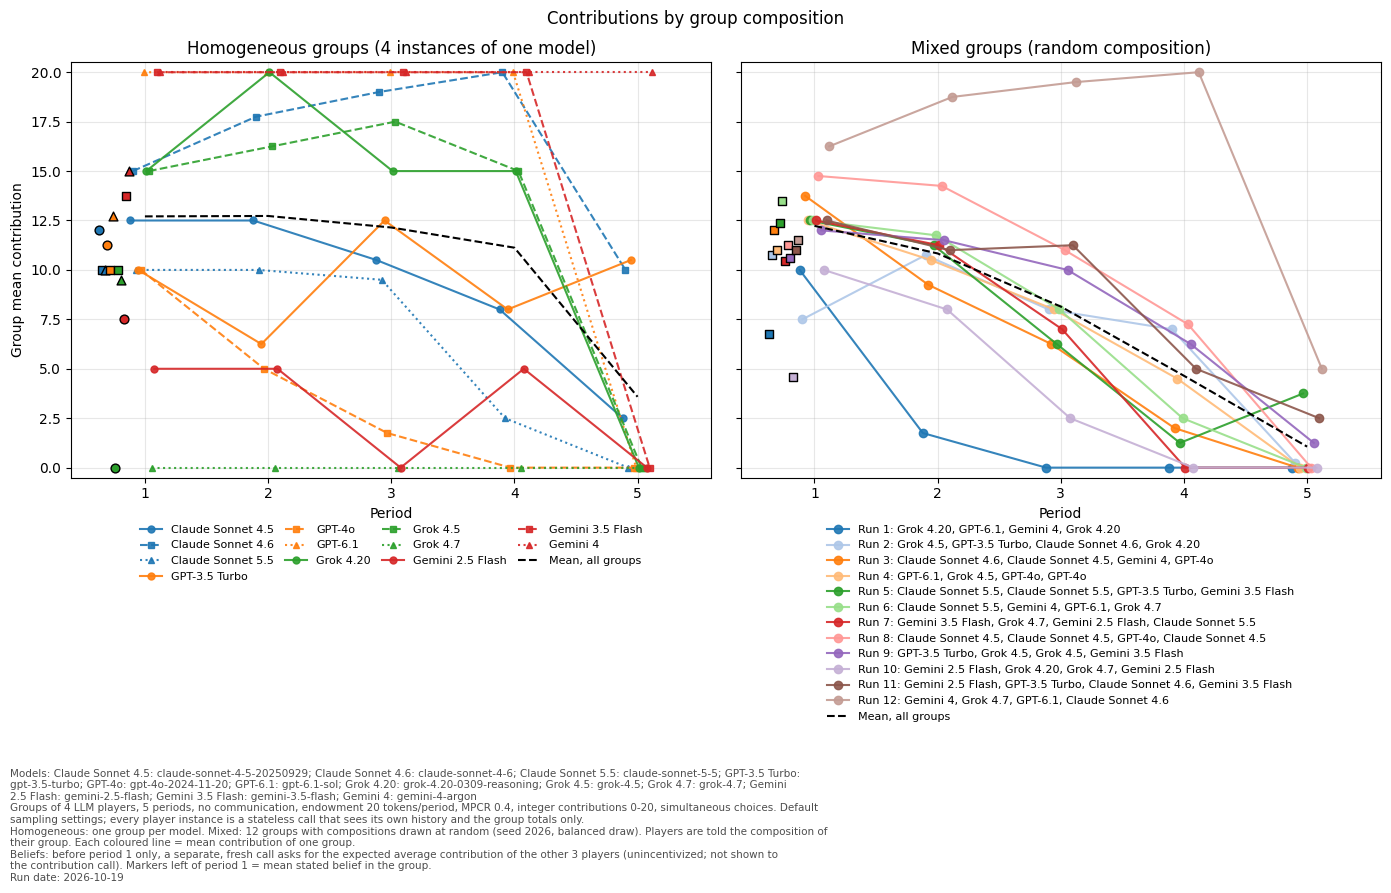

In [11]:
# ---- Summary: mean contribution per model, homogeneous vs mixed ---------------------------------------------
by_mt = results.groupby(["model", "treatment"])
summary = pd.concat(
    {
        "mean_all_periods": by_mt["contribution"].mean(),
        "mean_period1": results[results.period == 1].groupby(["model", "treatment"])["contribution"].mean(),
        "belief_period1": beliefs.groupby(["model", "treatment"])["belief_period1"].mean(),
        "n_player_periods": by_mt.size(),
    },
    axis=1,
).unstack("treatment").reindex(list(MODELS))
summary[("mean_all_periods", "homog - mixed")] = summary[("mean_all_periods", "homogeneous")] - summary[("mean_all_periods", "mixed")]
print("Mean contribution per model (all periods / period 1 / period-1 belief / number of player-periods):")
display(summary.round(2))

by_family = results.pivot_table(index="family", columns="treatment", values="contribution", aggfunc=["mean", "size"]).reindex(FAMILIES)
print("\nMean contribution per model family (provider level):")
display(by_family.round(2))

group_means = results.groupby(["treatment", "run", "composition", "period"])["contribution"].mean().unstack("period")
print("\nGroup mean contribution per period:")
display(group_means.round(2))

# ---- Figure -----------------------------------------------------------------------------------------------
# Left: homogeneous groups, one line per group (= per model). Right: mixed groups, one line per group (run).
# Colour = model family, line style / marker = version within the family
family_colors = dict(zip(FAMILIES, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
styles = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D")]
model_style = {}
for fam in FAMILIES:
    for k, m in enumerate(m for m in MODELS if MODELS[m]["family"] == fam):
        model_style[m] = (family_colors[fam], *styles[k % len(styles)])
run_colors = plt.get_cmap("tab20" if RUNS_PER_TREATMENT > 8 else "Dark2").colors
periods = np.arange(1, N_PERIODS + 1)
offsets = np.linspace(-0.12, 0.12, max(len(MODELS), RUNS_PER_TREATMENT))  # fixed offsets so identical choices stay visible

fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)

hom, bh = results[results.treatment == "homogeneous"], beliefs[beliefs.treatment == "homogeneous"]
ax = axes[0]
for i, m in enumerate(MODELS):
    gm = hom[hom.model == m].groupby("period")["contribution"].mean().reindex(periods)
    color, ls, marker = model_style[m]
    ax.plot(periods + offsets[i], gm, ls=ls, marker=marker, ms=5, color=color, alpha=0.9,
            label=m, zorder=2)
    ax.scatter([1 + offsets[i] - 0.25], [bh.loc[bh.model == m, "belief_period1"].mean()], marker=marker, s=40,
               color=color, edgecolor="k", zorder=3)
ax.plot(periods, hom.groupby("period")["contribution"].mean().reindex(periods), color="k", ls="--", label="Mean, all groups")
ax.set_title("Homogeneous groups (4 instances of one model)")

mix, bm = results[results.treatment == "mixed"], beliefs[beliefs.treatment == "mixed"]
ax = axes[1]
for i, ((run, comp), g) in enumerate(mix.groupby(["run", "composition"])):
    gm = g.groupby("period")["contribution"].mean().reindex(periods)
    ax.plot(periods + offsets[i], gm, marker="o", color=run_colors[i], alpha=0.9,
            label=f"Run {run}: {comp.replace('+', ', ')}", zorder=2)
    ax.scatter([1 + offsets[i] - 0.25], [bm.loc[bm.run == run, "belief_period1"].mean()], marker="s", s=40,
               color=run_colors[i], edgecolor="k", zorder=3)
ax.plot(periods, mix.groupby("period")["contribution"].mean().reindex(periods), color="k", ls="--", label="Mean, all groups")
ax.set_title("Mixed groups (random composition)")

for ax in axes:
    ax.set(xlabel="Period", ylim=(-0.5, ENDOWMENT + 0.5), xlim=(0.4, N_PERIODS + 0.6))
    ax.set_xticks(periods)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), frameon=False, ncol=4, fontsize=8, columnspacing=1)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), frameon=False, ncol=1, fontsize=8)
axes[0].set_ylabel("Group mean contribution")
fig.suptitle("Contributions by group composition")

models_txt = "; ".join(f"{n}: {p['model']}" for n, p in MODELS.items())
paras = [
    f"Models: {models_txt}",
    f"Groups of {GROUP_SIZE} LLM players, {N_PERIODS} periods, no communication, endowment {ENDOWMENT} tokens/period, "
    f"MPCR {MPCR}, integer contributions 0-{ENDOWMENT}, simultaneous choices. Default sampling settings; every player "
    "instance is a stateless call that sees its own history and the group totals only.",
    f"Homogeneous: one group per model. Mixed: {RUNS_PER_TREATMENT} groups with compositions drawn at random "
    f"(seed {SEED}, {'balanced' if BALANCED_MIXED else 'i.i.d.'} draw). Players {'are' if DISCLOSE_COMPOSITION else 'are not'} "
    "told the composition of their group. Each coloured line = mean contribution of one group.",
    f"Beliefs: before period 1 only, a separate, fresh call asks for the expected average contribution of the other "
    f"{GROUP_SIZE - 1} players (unincentivized; not shown to the contribution call). Markers left of period 1 = "
    "mean stated belief in the group.",
    f"Run date: {pd.Timestamp.now():%Y-%m-%d}",
]
fig.text(0.01, 0.01, "\n".join(textwrap.fill(p, 150) for p in paras), ha="left", va="bottom", fontsize=7.5, color="0.3")
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.savefig("contributions.png", dpi=150)
plt.show()

In [12]:
# ---- Treatment comparison: means and distributions ---------------------------------------------------------
from scipy import stats


def describe(s):
    return pd.Series({
        "n": len(s), "mean": s.mean(), "sd": s.std(ddof=1), "min": s.min(), "p25": s.quantile(0.25),
        "median": s.median(), "p75": s.quantile(0.75), "max": s.max(),
        "share zero": (s == 0).mean(), "share full": (s == ENDOWMENT).mean(),
    })


# Player-period level: one observation per player and period (not independent within a group)
dist_players = results.groupby("treatment")["contribution"].apply(describe).unstack()
print("Contributions per player-period, by treatment:")
display(dist_players.round(2))

# Group level: one observation per group (= run), its mean contribution over all periods
group_mean = results.groupby(["treatment", "run"])["contribution"].mean()
dist_groups = group_mean.groupby("treatment").apply(describe).unstack().drop(columns=["share zero", "share full"])
u, p_mw = stats.mannwhitneyu(group_mean["homogeneous"], group_mean["mixed"], alternative="two-sided")
print(f"\nGroup mean contribution (one observation per group): Mann-Whitney U = {u:.1f}, p = {p_mw:.3f}")
display(dist_groups.round(2))

# Means by treatment and period, with the period-1 belief for comparison
by_period = results.pivot_table(index="treatment", columns="period", values="contribution", aggfunc="mean")
by_period.columns = [f"period {c}" for c in by_period.columns]
by_period.insert(0, "belief (period 1)", beliefs.groupby("treatment")["belief_period1"].mean())
by_period["all periods"] = results.groupby("treatment")["contribution"].mean()
print("\nMean contribution by treatment and period:")
display(by_period.round(2))

pd.concat({"player_periods": dist_players, "groups": dist_groups, "by_period": by_period}, names=["level"]).to_csv("treatment_summary.csv")

Contributions per player-period, by treatment:


,n,mean,sd,min,p25,median,p75,max,share zero,share full
treatment,,,,,,,,,,
homogeneous,240.0,10.46,8.55,0.0,0.0,10.0,20.0,20.0,0.32,0.35
mixed,240.0,7.38,6.72,0.0,0.0,9.5,10.0,20.0,0.37,0.11



Group mean contribution (one observation per group): Mann-Whitney U = 96.5, p = 0.166


,n,mean,sd,min,p25,median,p75,max
treatment,,,,,,,,
homogeneous,12.0,10.46,6.28,0.00,5.64,11.10,16.00,20.0
mixed,12.0,7.38,3.28,2.35,6.22,6.98,8.26,15.9



Mean contribution by treatment and period:


,belief (period 1),period 1,period 2,period 3,period 4,period 5,all periods
treatment,,,,,,,
homogeneous,10.15,12.71,12.73,12.15,11.12,3.58,10.46
mixed,10.48,12.23,10.83,8.15,4.65,1.06,7.38
